# Odoo Product Demand Forecasting — Rolling Cross-Validation Version

This is a **new notebook** so you can keep the previous notebook unchanged.

This version forecasts **weekly product demand quantity** and uses:

- simple baselines
- Croston
- Syntetos-Boylan Approximation (SBA)
- rolling time-series cross-validation
- walk-forward prediction on the untouched test set
- 12-week future forecasting
- batch evaluation across multiple Stock Keeping Units (SKUs)

## PostgreSQL query

Run this in pgAdmin and export as `../input/weekly_product_demand.csv`.

```sql
WITH params AS (
    SELECT
        DATE '2025-01-06' AS start_date,
        (
            DATE_TRUNC(
                'week',
                (CURRENT_TIMESTAMP AT TIME ZONE 'Asia/Kolkata')::date
            )::date - 1
        ) AS last_complete_sunday
),
sales_lines AS (
    SELECT
        (
            so.date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
        )::date AS sale_date,
        sol.product_id,
        pp.default_code,
        sol.product_uom_id AS uom_id,
        sol.product_uom_qty AS ordered_qty,
        so.id AS order_id
    FROM sale_order_line sol
    JOIN sale_order so
        ON so.id = sol.order_id
    LEFT JOIN product_product pp
        ON pp.id = sol.product_id
    CROSS JOIN params p
    WHERE so.state IN ('sale', 'done')
      AND sol.display_type IS NULL
      AND sol.product_id IS NOT NULL
      AND sol.product_uom_qty > 0
      AND (
            so.date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
          )::date >= p.start_date
      AND (
            so.date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
          )::date <= p.last_complete_sunday
)
SELECT
    (
        DATE_TRUNC('week', sale_date)::date + 6
    ) AS week_ending,
    product_id,
    default_code,
    uom_id,
    SUM(ordered_qty) AS weekly_demand_qty,
    COUNT(DISTINCT order_id) AS order_count
FROM sales_lines
GROUP BY
    1,
    product_id,
    default_code,
    uom_id
ORDER BY
    week_ending,
    product_id,
    uom_id;
```

## Install packages

In [1]:
!pip install pandas numpy matplotlib scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Imports

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

## Load data

In [3]:
df = pd.read_csv(\"../input/../input/weekly_product_demand.csv\")
df.head()

,week_ending,product_id,default_code,uom_id,weekly_demand_qty,order_count
0,2025-01-12,4199,JU0001,1,24.0,1
1,2025-01-12,4200,JU0003,1,96.0,4
2,2025-01-12,4201,JU0004,1,510.0,3
3,2025-01-12,4202,JU0006,1,1580.0,8
4,2025-01-12,4203,JU0008,1,24.0,1


## Clean data

In [4]:
df["week_ending"] = pd.to_datetime(df["week_ending"])

df["product_id"] = pd.to_numeric(
    df["product_id"], errors="coerce"
).astype("Int64")

df["uom_id"] = pd.to_numeric(
    df["uom_id"], errors="coerce"
).astype("Int64")

df["weekly_demand_qty"] = pd.to_numeric(
    df["weekly_demand_qty"], errors="coerce"
)

df["order_count"] = pd.to_numeric(
    df["order_count"], errors="coerce"
)

df = df.dropna(
    subset=[
        "week_ending",
        "product_id",
        "uom_id",
        "weekly_demand_qty"
    ]
)

df = df.sort_values(
    ["product_id", "uom_id", "week_ending"]
)

print("Shape:", df.shape)
df.head()

Shape: (6040, 6)


,week_ending,product_id,default_code,uom_id,weekly_demand_qty,order_count
0,2025-01-12,4199,JU0001,1,24.0,1
144,2025-01-26,4199,JU0001,1,162.0,16
303,2025-02-02,4199,JU0001,1,402.0,34
478,2025-02-09,4199,JU0001,1,126.0,6
638,2025-02-16,4199,JU0001,1,144.0,6


## Create complete weekly timeline

In [5]:
global_start = df["week_ending"].min()
global_end = df["week_ending"].max()

all_weeks = pd.date_range(
    start=global_start,
    end=global_end,
    freq="W-SUN"
)

print("First week:", global_start)
print("Last complete week:", global_end)
print("Number of weeks:", len(all_weeks))

First week: 2025-01-12 00:00:00
Last complete week: 2026-08-09 00:00:00
Number of weeks: 83


## Create SKU identifiers

In [6]:
df["sku_key"] = (
    df["product_id"].astype(str)
    + "_UOM_"
    + df["uom_id"].astype(str)
)

df["sku_code"] = df["default_code"].fillna(
    "PRODUCT_" + df["product_id"].astype(str)
)

df[[
    "sku_key",
    "sku_code",
    "product_id",
    "uom_id"
]].drop_duplicates().head(20)

,sku_key,sku_code,product_id,uom_id
0,4199_UOM_1,JU0001,4199,1
1,4200_UOM_1,JU0003,4200,1
2,4201_UOM_1,JU0004,4201,1
3,4202_UOM_1,JU0006,4202,1
4,4203_UOM_1,JU0008,4203,1
5,4204_UOM_1,JU0010,4204,1
3318,4205_UOM_1,PRODUCT_4205,4205,1
6,4206_UOM_1,JU0012,4206,1
7,4207_UOM_1,JU0011,4207,1
8,4208_UOM_1,JU0014,4208,1


## Build complete weekly series for one SKU

In [7]:
def build_weekly_series(dataframe, sku_key, all_weeks):

    sku_df = dataframe[
        dataframe["sku_key"] == sku_key
    ].copy()

    if sku_df.empty:
        raise ValueError(
            f"No data found for SKU key: {sku_key}"
        )

    series = (
        sku_df
        .groupby("week_ending")["weekly_demand_qty"]
        .sum()
        .reindex(all_weeks, fill_value=0.0)
    )

    series.index.name = "week_ending"
    series.name = "weekly_demand_qty"

    return series

## Profile all SKUs

In [8]:
profile_rows = []

unique_skus = (
    df[[
        "sku_key",
        "sku_code",
        "product_id",
        "uom_id"
    ]]
    .drop_duplicates()
)

for _, row in unique_skus.iterrows():

    sku = row["sku_key"]

    series_tmp = build_weekly_series(
        df,
        sku,
        all_weeks
    )

    nonzero = series_tmp[
        series_tmp > 0
    ]

    profile_rows.append({
        "sku_key": sku,
        "sku_code": row["sku_code"],
        "product_id": int(row["product_id"]),
        "uom_id": int(row["uom_id"]),
        "total_demand": series_tmp.sum(),
        "active_weeks": int((series_tmp > 0).sum()),
        "zero_weeks": int((series_tmp == 0).sum()),
        "zero_week_pct": (series_tmp == 0).mean() * 100,
        "avg_nonzero_demand": (
            nonzero.mean() if len(nonzero) > 0 else 0
        ),
        "max_weekly_demand": series_tmp.max()
    })

product_profile = (
    pd.DataFrame(profile_rows)
    .sort_values(
        "total_demand",
        ascending=False
    )
)

product_profile.head(20)

,sku_key,sku_code,product_id,uom_id,total_demand,active_weeks,zero_weeks,zero_week_pct,avg_nonzero_demand,max_weekly_demand
60,4259_UOM_1,JU0093,4259,1,215839.0,78,5,6.024096,2767.166667,35930.0
59,4258_UOM_1,JU0090,4258,1,139556.0,76,7,8.433735,1836.263158,26268.0
3,4202_UOM_1,JU0006,4202,1,52549.0,67,16,19.277108,784.313433,8842.0
11,4210_UOM_1,JU0018,4210,1,27722.0,52,31,37.349398,533.115385,5059.0
169,4370_UOM_1,JMP0048,4370,1,27684.0,65,18,21.686747,425.907692,3124.0
62,4261_UOM_1,JU0096,4261,1,27625.0,52,31,37.349398,531.250000,6750.0
14,4213_UOM_1,JU0020,4213,1,26175.0,61,22,26.506024,429.098361,4812.0
106,4306_UOM_1,JUO241,4306,1,23781.0,58,25,30.120482,410.017241,4056.0
117,4317_UOM_1,JMP0068,4317,1,23730.0,28,55,66.265060,847.500000,3092.0
105,4305_UOM_1,JU0196,4305,1,22722.0,75,8,9.638554,302.960000,3917.0


## Select product

In [9]:
TARGET_PRODUCT_ID = None
TARGET_UOM_ID = None

if TARGET_PRODUCT_ID is None:

    selected = product_profile.iloc[0]

else:

    candidates = product_profile[
        product_profile["product_id"]
        == TARGET_PRODUCT_ID
    ]

    if TARGET_UOM_ID is not None:
        candidates = candidates[
            candidates["uom_id"]
            == TARGET_UOM_ID
        ]

    if candidates.empty:
        raise ValueError(
            "No matching product/unit-of-measure series found."
        )

    selected = candidates.iloc[0]

TARGET_SKU_KEY = selected["sku_key"]

print("Selected SKU key :", TARGET_SKU_KEY)
print("SKU code         :", selected["sku_code"])
print("Product ID       :", selected["product_id"])
print("Unit of measure  :", selected["uom_id"])
print("Total demand     :", selected["total_demand"])
print("Active weeks     :", selected["active_weeks"])
print("Zero-week %      :", round(selected["zero_week_pct"], 2))

Selected SKU key : 4259_UOM_1
SKU code         : JU0093
Product ID       : 4259
Unit of measure  : 1
Total demand     : 215839.0
Active weeks     : 78
Zero-week %      : 6.02


## Build selected SKU series

In [10]:
series = build_weekly_series(
    df,
    TARGET_SKU_KEY,
    all_weeks
)

series.head(20)

week_ending
2025-01-12     5826.0
2025-01-19      108.0
2025-01-26    14837.0
2025-02-02    35930.0
2025-02-09     9668.0
2025-02-16     9370.0
2025-02-23     6846.0
2025-03-02     1899.0
2025-03-09     3627.0
2025-03-16     3831.0
2025-03-23    14102.0
2025-03-30     2784.0
2025-04-06     4134.0
2025-04-13     6039.0
2025-04-20     4204.0
2025-04-27     7805.0
2025-05-04     3073.0
2025-05-11     3597.0
2025-05-18     5819.0
2025-05-25     3222.0
Freq: W-SUN, Name: weekly_demand_qty, dtype: float64

## Plot weekly demand

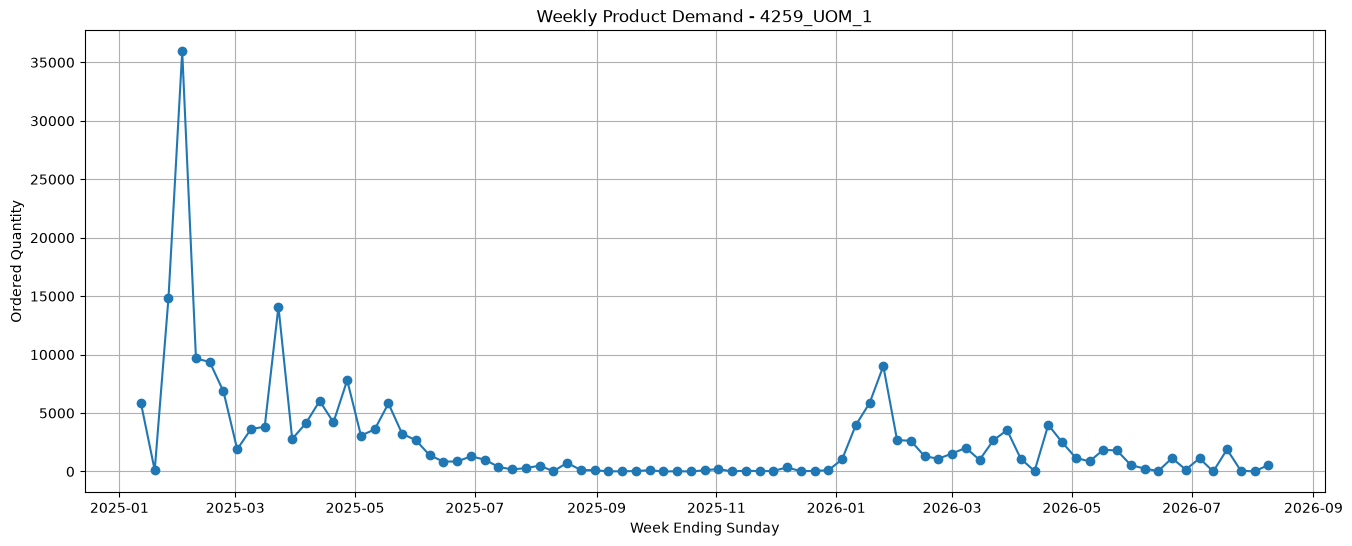

In [11]:
plt.figure(figsize=(16, 6))
plt.plot(
    series.index,
    series.values,
    marker="o"
)

plt.title(
    "Weekly Product Demand - "
    + TARGET_SKU_KEY
)

plt.xlabel("Week Ending Sunday")
plt.ylabel("Ordered Quantity")
plt.grid(True)
plt.show()

## Train/Test split

In [12]:
if len(series) >= 40:
    test_size = min(
        12,
        max(8, len(series) // 5)
    )
else:
    test_size = max(
        4,
        len(series) // 5
    )

train = series.iloc[:-test_size]
test = series.iloc[-test_size:]

print("Training weeks:", len(train))
print("Testing weeks :", len(test))
print("Train:", train.index.min(), "->", train.index.max())
print("Test :", test.index.min(), "->", test.index.max())

Training weeks: 71
Testing weeks : 12
Train: 2025-01-12 00:00:00 -> 2026-05-17 00:00:00
Test : 2026-05-24 00:00:00 -> 2026-08-09 00:00:00


## Plot Train/Test

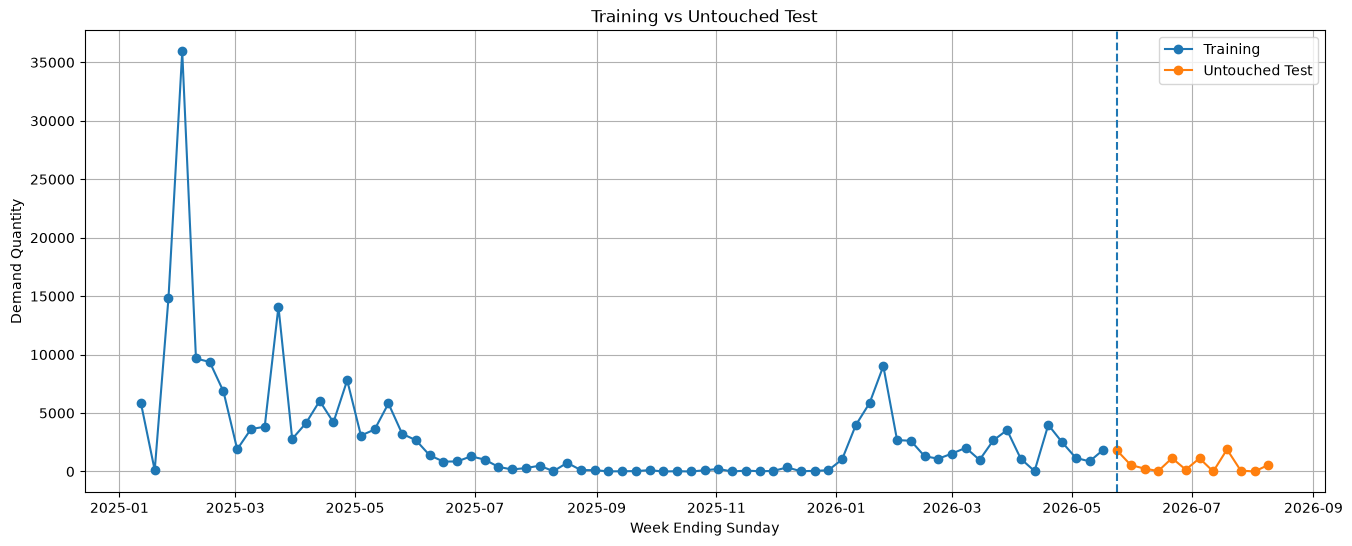

In [13]:
plt.figure(figsize=(16, 6))

plt.plot(
    train.index,
    train.values,
    marker="o",
    label="Training"
)

plt.plot(
    test.index,
    test.values,
    marker="o",
    label="Untouched Test"
)

plt.axvline(
    test.index.min(),
    linestyle="--"
)

plt.title("Training vs Untouched Test")
plt.xlabel("Week Ending Sunday")
plt.ylabel("Demand Quantity")
plt.legend()
plt.grid(True)
plt.show()

## Evaluation metrics

In [14]:
def wape(actual, predicted):

    actual = np.asarray(
        actual,
        dtype=float
    )

    predicted = np.asarray(
        predicted,
        dtype=float
    )

    denominator = np.sum(
        np.abs(actual)
    )

    if denominator == 0:
        return np.nan

    return (
        np.sum(
            np.abs(actual - predicted)
        )
        / denominator
    ) * 100


def get_metrics(actual, predicted):

    return {
        "MAE": mean_absolute_error(
            actual,
            predicted
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                actual,
                predicted
            )
        ),

        "WAPE": wape(
            actual,
            predicted
        )
    }


def evaluate_model(actual, predicted, name):

    metrics = get_metrics(
        actual,
        predicted
    )

    print(name)
    print("-" * 50)
    print(
        f"Mean Absolute Error: "
        f"{metrics['MAE']:,.3f}"
    )
    print(
        f"Root Mean Squared Error: "
        f"{metrics['RMSE']:,.3f}"
    )
    print(
        f"Weighted Absolute Percentage Error: "
        f"{metrics['WAPE']:.2f}%"
    )

    return metrics

## Last-week naive baseline

In [15]:
last_week_value = train.iloc[-1]

last_week_naive = np.repeat(
    last_week_value,
    len(test)
)

evaluate_model(
    test,
    last_week_naive,
    "Last-Week Naive"
)

Last-Week Naive
--------------------------------------------------
Mean Absolute Error: 1,228.417
Root Mean Squared Error: 1,391.550
Weighted Absolute Percentage Error: 194.09%


{'MAE': 1228.4166666666667,
 'RMSE': np.float64(1391.5504841722416),
 'WAPE': np.float64(194.0882159315339)}

## Four-week mean baseline

In [16]:
four_week_mean_value = train.tail(4).mean()

four_week_mean_predictions = np.repeat(
    four_week_mean_value,
    len(test)
)

evaluate_model(
    test,
    four_week_mean_predictions,
    "Four-Week Mean"
)

Four-Week Mean
--------------------------------------------------
Mean Absolute Error: 1,047.750
Root Mean Squared Error: 1,172.503
Weighted Absolute Percentage Error: 165.54%


{'MAE': 1047.75,
 'RMSE': np.float64(1172.502985070827),
 'WAPE': np.float64(165.54312047399605)}

## Four-week median baseline

In [17]:
four_week_median_value = train.tail(4).median()

four_week_median_predictions = np.repeat(
    four_week_median_value,
    len(test)
)

evaluate_model(
    test,
    four_week_median_predictions,
    "Four-Week Median"
)

Four-Week Median
--------------------------------------------------
Mean Absolute Error: 988.750
Root Mean Squared Error: 1,100.686
Weighted Absolute Percentage Error: 156.22%


{'MAE': 988.75,
 'RMSE': np.float64(1100.6862632012812),
 'WAPE': np.float64(156.22119815668202)}

## Croston and SBA implementation

In [18]:
def croston_fit(
    series,
    alpha=0.1,
    variant="classic"
):

    y = np.asarray(
        series,
        dtype=float
    )

    if len(y) == 0:
        raise ValueError(
            "Series must not be empty."
        )

    nonzero_idx = np.flatnonzero(
        y > 0
    )

    if len(nonzero_idx) == 0:

        return {
            "forecast": 0.0,
            "demand_estimate": 0.0,
            "interval_estimate": np.inf,
            "alpha": alpha,
            "variant": variant
        }

    first = nonzero_idx[0]

    z = y[first]
    p = first + 1
    interval = 1

    for t in range(
        first + 1,
        len(y)
    ):

        if y[t] > 0:

            z = (
                alpha * y[t]
                + (1 - alpha) * z
            )

            p = (
                alpha * interval
                + (1 - alpha) * p
            )

            interval = 1

        else:

            interval += 1

    forecast = z / p

    if variant.lower() == "sba":
        forecast = (
            1 - alpha / 2
        ) * forecast

    return {
        "forecast": max(
            float(forecast),
            0.0
        ),
        "demand_estimate": float(z),
        "interval_estimate": float(p),
        "alpha": float(alpha),
        "variant": variant
    }

## Initial Croston and SBA at alpha = 0.1

In [19]:
croston_initial = croston_fit(
    train,
    alpha=0.1,
    variant="classic"
)

croston_initial_predictions = np.repeat(
    croston_initial["forecast"],
    len(test)
)

sba_initial = croston_fit(
    train,
    alpha=0.1,
    variant="sba"
)

sba_initial_predictions = np.repeat(
    sba_initial["forecast"],
    len(test)
)

evaluate_model(
    test,
    croston_initial_predictions,
    "Initial Croston alpha=0.1"
)

print()

evaluate_model(
    test,
    sba_initial_predictions,
    "Initial SBA alpha=0.1"
)

Initial Croston alpha=0.1
--------------------------------------------------
Mean Absolute Error: 1,223.172
Root Mean Squared Error: 1,386.022
Weighted Absolute Percentage Error: 193.26%

Initial SBA alpha=0.1
--------------------------------------------------
Mean Absolute Error: 1,152.897
Root Mean Squared Error: 1,305.580
Weighted Absolute Percentage Error: 182.16%


{'MAE': 1152.8973097488013,
 'RMSE': np.float64(1305.5803552925263),
 'WAPE': np.float64(182.15625697150247)}

# Rolling Time-Series Cross-Validation

The test set stays untouched.

For each Croston-family variant and alpha value, the training data is evaluated over multiple rolling validation windows.

## Rolling cross-validation function

In [20]:
def rolling_cv_croston(
    train,
    alpha_grid,
    variants=("classic", "sba"),
    initial_train_weeks=30,
    validation_weeks=4,
    step_weeks=4
):

    results = []
    fold_detail_rows = []

    for variant in variants:

        for alpha in alpha_grid:

            fold_metrics = []

            train_end = initial_train_weeks
            fold_number = 1

            while (
                train_end
                + validation_weeks
                <= len(train)
            ):

                fold_train = train.iloc[
                    :train_end
                ]

                fold_validation = train.iloc[
                    train_end:
                    train_end + validation_weeks
                ]

                model = croston_fit(
                    fold_train,
                    alpha=float(alpha),
                    variant=variant
                )

                predictions = np.repeat(
                    model["forecast"],
                    len(fold_validation)
                )

                metrics = get_metrics(
                    fold_validation,
                    predictions
                )

                fold_metrics.append(
                    metrics
                )

                fold_detail_rows.append({
                    "variant": variant,
                    "alpha": float(alpha),
                    "fold": fold_number,
                    "train_end": fold_train.index.max(),
                    "validation_start": fold_validation.index.min(),
                    "validation_end": fold_validation.index.max(),
                    "MAE": metrics["MAE"],
                    "RMSE": metrics["RMSE"],
                    "WAPE": metrics["WAPE"]
                })

                train_end += step_weeks
                fold_number += 1

            if len(fold_metrics) > 0:

                fold_df = pd.DataFrame(
                    fold_metrics
                )

                results.append({
                    "variant": variant,
                    "alpha": float(alpha),
                    "folds": len(fold_df),
                    "mean_MAE": fold_df["MAE"].mean(),
                    "mean_RMSE": fold_df["RMSE"].mean(),
                    "mean_WAPE": fold_df["WAPE"].mean(),
                    "median_WAPE": fold_df["WAPE"].median(),
                    "std_WAPE": fold_df["WAPE"].std()
                })

    summary = (
        pd.DataFrame(results)
        .sort_values(
            "mean_WAPE"
        )
        .reset_index(
            drop=True
        )
    )

    fold_details = pd.DataFrame(
        fold_detail_rows
    )

    return summary, fold_details

## Run rolling cross-validation

In [27]:
alpha_grid = np.arange(
    0.05,
    0.55,
    0.05
)

INITIAL_TRAIN_WEEKS = min(
    30,
    max(
        12,
        len(train) // 2
    )
)

VALIDATION_WEEKS = 4
STEP_WEEKS = 4

rolling_results, rolling_fold_details = (
    rolling_cv_croston(
        train=train,
        alpha_grid=alpha_grid,
        initial_train_weeks=INITIAL_TRAIN_WEEKS,
        validation_weeks=VALIDATION_WEEKS,
        step_weeks=STEP_WEEKS
    )
)

rolling_results.head(20)

,variant,alpha,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,std_WAPE
0,sba,0.50,10,860.428650,1139.663320,99.675393,79.423808,60.938660
1,sba,0.45,10,853.801304,1147.920157,104.611026,78.773419,72.613547
2,sba,0.40,10,861.088962,1159.825441,112.058576,78.084699,87.268128
3,classic,0.50,10,952.983877,1157.312543,120.158217,79.775316,93.398246
4,sba,0.35,10,877.042331,1175.437628,122.679615,77.358491,108.362819
5,classic,0.45,10,951.123696,1165.677470,125.127859,85.462459,104.520600
6,classic,0.40,10,950.130583,1177.887997,131.899758,90.501216,119.045193
7,sba,0.30,10,907.757813,1196.422881,140.179086,80.362574,142.268448
8,classic,0.35,10,949.873783,1194.640458,142.024635,90.821297,140.095606
9,classic,0.30,10,947.789820,1217.752692,161.781651,90.795912,176.975128


## Select best cross-validation configuration

In [22]:
best_cv_row = rolling_results.iloc[0]

best_variant = best_cv_row["variant"]
best_alpha = float(
    best_cv_row["alpha"]
)

print("Best variant:", best_variant.upper())
print("Best alpha:", best_alpha)
print(
    "Number of folds:",
    int(best_cv_row["folds"])
)
print(
    "Average CV WAPE:",
    round(
        best_cv_row["mean_WAPE"],
        2
    ),
    "%"
)
print(
    "Median CV WAPE:",
    round(
        best_cv_row["median_WAPE"],
        2
    ),
    "%"
)
print(
    "CV WAPE standard deviation:",
    round(
        best_cv_row["std_WAPE"],
        2
    )
)

Best variant: SBA
Best alpha: 0.5
Number of folds: 10
Average CV WAPE: 99.68 %
Median CV WAPE: 79.42 %
CV WAPE standard deviation: 60.94


## Inspect folds for the winning configuration

In [28]:
best_fold_details = (
    rolling_fold_details[
        (
            rolling_fold_details["variant"]
            == best_variant
        )
        &
        (
            np.isclose(
                rolling_fold_details["alpha"],
                best_alpha
            )
        )
    ]
)

best_fold_details

,variant,alpha,fold,train_end,validation_start,validation_end,MAE,RMSE,WAPE
190,sba,0.5,1,2025-08-03,2025-08-10,2025-08-31,285.250152,296.900317,113.872316
191,sba,0.5,2,2025-08-31,2025-09-07,2025-09-28,111.375019,118.558350,246.132639
192,sba,0.5,3,2025-09-28,2025-10-05,2025-10-26,49.816407,51.253984,153.281252
193,sba,0.5,4,2025-10-26,2025-11-02,2025-11-23,67.500000,95.394323,84.905660
194,sba,0.5,5,2025-11-23,2025-11-30,2025-12-21,88.175781,156.391019,73.941955
195,sba,0.5,6,2025-12-21,2025-12-28,2026-01-18,2679.441907,3527.983586,97.736345
196,sba,0.5,7,2026-01-18,2026-01-25,2026-02-15,2119.391892,3123.201341,54.197466
197,sba,0.5,8,2026-02-15,2026-02-22,2026-03-15,527.090204,600.314675,37.355790
198,sba,0.5,9,2026-03-15,2026-03-22,2026-04-12,1283.773549,1563.132233,70.055855
199,sba,0.5,10,2026-04-12,2026-04-19,2026-05-10,1392.471588,1863.503371,65.274656


## Plot cross-validation WAPE by fold

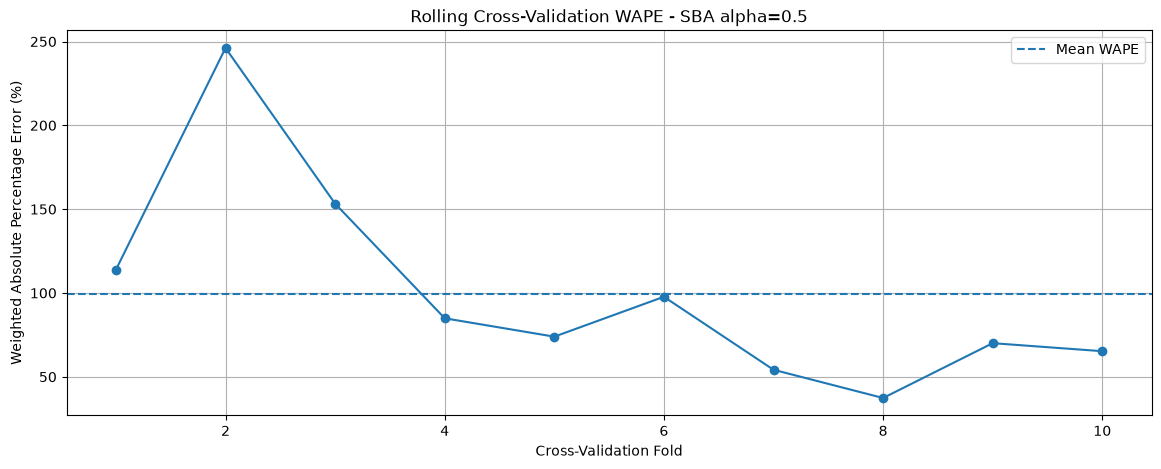

In [29]:
plt.figure(figsize=(14, 5))

plt.plot(
    best_fold_details["fold"],
    best_fold_details["WAPE"],
    marker="o"
)

plt.axhline(
    best_fold_details["WAPE"].mean(),
    linestyle="--",
    label="Mean WAPE"
)

plt.title(
    "Rolling Cross-Validation WAPE - "
    f"{best_variant.upper()} "
    f"alpha={best_alpha}"
)

plt.xlabel("Cross-Validation Fold")
plt.ylabel(
    "Weighted Absolute Percentage Error (%)"
)

plt.legend()
plt.grid(True)
plt.show()

# Walk-Forward Prediction on the Untouched Final Test Set

This is the main evaluation.

Each test week is forecast using only the information available before that week. After the actual demand becomes known, it is appended to history before the next forecast.

## Walk-forward prediction

In [30]:
history = list(
    train.values
)

cv_walk_forward_predictions = []

for actual_value in test.values:

    model = croston_fit(
        history,
        alpha=best_alpha,
        variant=best_variant
    )

    prediction = model["forecast"]

    cv_walk_forward_predictions.append(
        prediction
    )

    history.append(
        float(actual_value)
    )

cv_walk_forward_predictions = pd.Series(
    cv_walk_forward_predictions,
    index=test.index,
    name="forecast_qty"
)

cv_walk_forward_predictions

week_ending
2026-05-24    1202.032133
2026-05-31    1275.266066
2026-06-07     844.633034
2026-06-14     514.566518
2026-06-21     273.033259
2026-06-28     566.266629
2026-07-05     342.758315
2026-07-12     594.379157
2026-07-19     594.379157
2026-07-26     670.126386
2026-08-02     425.475831
2026-08-09     425.475831
Freq: W-SUN, Name: forecast_qty, dtype: float64

## Evaluate walk-forward model

In [31]:
cv_walk_metrics = evaluate_model(
    test,
    cv_walk_forward_predictions,
    (
        "Rolling CV + Walk-Forward "
        + best_variant.upper()
    )
)

Rolling CV + Walk-Forward SBA
--------------------------------------------------
Mean Absolute Error: 624.503
Root Mean Squared Error: 681.937
Weighted Absolute Percentage Error: 98.67%


## Compare final test models

In [32]:
comparison_metrics = pd.DataFrame(
    [
        {
            "Model": "Last-Week Naive",
            **get_metrics(
                test,
                last_week_naive
            )
        },
        {
            "Model": "Four-Week Mean",
            **get_metrics(
                test,
                four_week_mean_predictions
            )
        },
        {
            "Model": "Four-Week Median",
            **get_metrics(
                test,
                four_week_median_predictions
            )
        },
        {
            "Model": "Initial Croston alpha=0.1",
            **get_metrics(
                test,
                croston_initial_predictions
            )
        },
        {
            "Model": "Initial SBA alpha=0.1",
            **get_metrics(
                test,
                sba_initial_predictions
            )
        },
        {
            "Model": (
                "Rolling CV + Walk-Forward "
                + best_variant.upper()
            ),
            **get_metrics(
                test,
                cv_walk_forward_predictions
            )
        }
    ]
)

comparison_metrics = (
    comparison_metrics
    .sort_values("WAPE")
    .reset_index(drop=True)
)

comparison_metrics

,Model,MAE,RMSE,WAPE
0,Rolling CV + Walk-Forward SBA,624.502911,681.937261,98.670638
1,Four-Week Median,988.750000,1100.686263,156.221198
2,Four-Week Mean,1047.750000,1172.502985,165.543120
3,Initial SBA alpha=0.1,1152.897310,1305.580355,182.156257
4,Initial Croston alpha=0.1,1223.171899,1386.021958,193.259550
5,Last-Week Naive,1228.416667,1391.550484,194.088216


## Identify winner

In [33]:
winner = comparison_metrics.iloc[0]

print(
    "Best final test model:",
    winner["Model"]
)

print(
    "Final test WAPE:",
    round(winner["WAPE"], 2),
    "%"
)

print(
    "Final test MAE:",
    round(winner["MAE"], 3)
)

print(
    "Final test RMSE:",
    round(winner["RMSE"], 3)
)

Best final test model: Rolling CV + Walk-Forward SBA
Final test WAPE: 98.67 %
Final test MAE: 624.503
Final test RMSE: 681.937


## Plot final test comparison

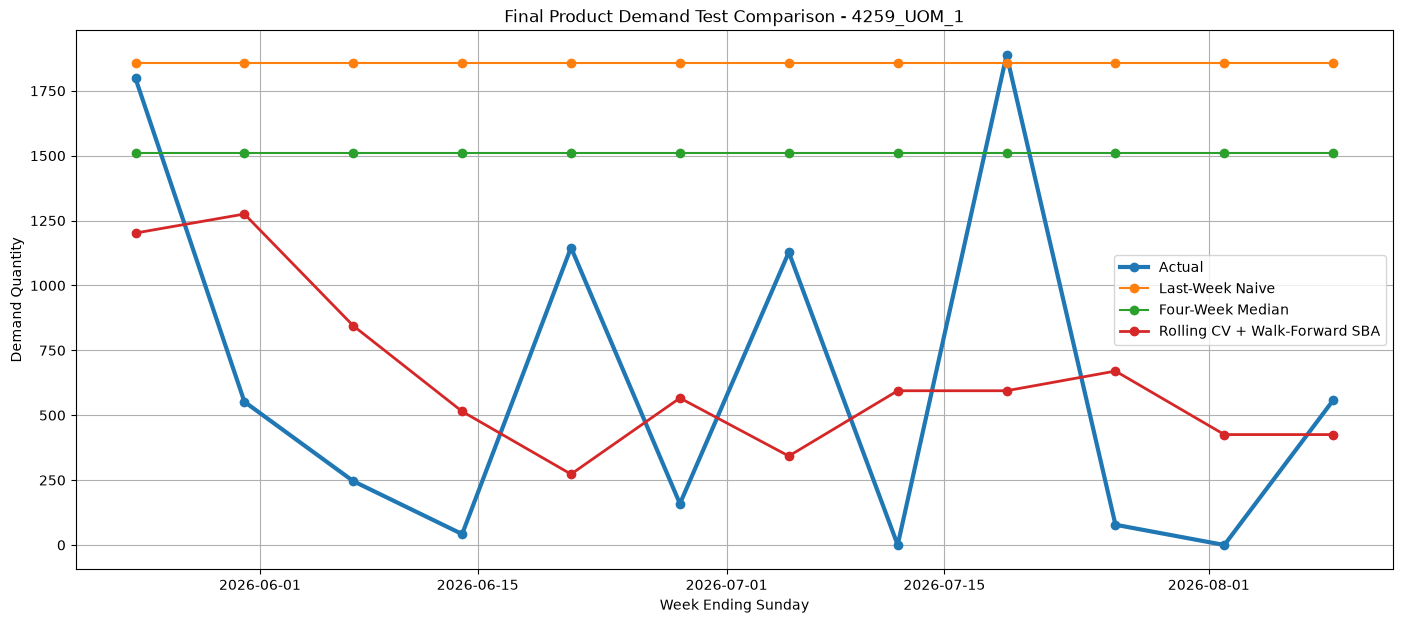

In [34]:
plt.figure(figsize=(17, 7))

plt.plot(
    test.index,
    test.values,
    marker="o",
    linewidth=3,
    label="Actual"
)

plt.plot(
    test.index,
    last_week_naive,
    marker="o",
    label="Last-Week Naive"
)

plt.plot(
    test.index,
    four_week_median_predictions,
    marker="o",
    label="Four-Week Median"
)

plt.plot(
    test.index,
    cv_walk_forward_predictions.values,
    marker="o",
    linewidth=2,
    label=(
        "Rolling CV + Walk-Forward "
        + best_variant.upper()
    )
)

plt.title(
    "Final Product Demand Test Comparison - "
    + TARGET_SKU_KEY
)

plt.xlabel("Week Ending Sunday")
plt.ylabel("Demand Quantity")

plt.legend()
plt.grid(True)
plt.show()

## Actual vs forecast table

In [35]:
final_test_comparison = pd.DataFrame({
    "actual": test,
    "last_week_naive": last_week_naive,
    "four_week_mean": four_week_mean_predictions,
    "four_week_median": four_week_median_predictions,
    "rolling_cv_walk_forward": cv_walk_forward_predictions
})

final_test_comparison

,actual,last_week_naive,four_week_mean,four_week_median,rolling_cv_walk_forward
week_ending,,,,,
2026-05-24,1798.0,1856.0,1599.5,1511.0,1202.032133
2026-05-31,552.0,1856.0,1599.5,1511.0,1275.266066
2026-06-07,246.0,1856.0,1599.5,1511.0,844.633034
2026-06-14,42.0,1856.0,1599.5,1511.0,514.566518
2026-06-21,1146.0,1856.0,1599.5,1511.0,273.033259
2026-06-28,159.0,1856.0,1599.5,1511.0,566.266629
2026-07-05,1128.0,1856.0,1599.5,1511.0,342.758315
2026-07-12,0.0,1856.0,1599.5,1511.0,594.379157
2026-07-19,1888.0,1856.0,1599.5,1511.0,594.379157


## Fit final model on all available complete history

In [36]:
final_model = croston_fit(
    series,
    alpha=best_alpha,
    variant=best_variant
)

final_model

{'forecast': 292.41378133560863,
 'demand_estimate': 633.5631928977193,
 'interval_estimate': 1.6250000000100044,
 'alpha': 0.5,
 'variant': 'sba'}

## Forecast next 12 weeks

In [37]:
FORECAST_WEEKS = 12

future_dates = pd.date_range(
    start=(
        series.index.max()
        + pd.Timedelta(weeks=1)
    ),
    periods=FORECAST_WEEKS,
    freq="W-SUN"
)

future_predictions = np.repeat(
    final_model["forecast"],
    FORECAST_WEEKS
)

future_df = pd.DataFrame({
    "week_ending": future_dates,
    "product_id": int(
        selected["product_id"]
    ),
    "uom_id": int(
        selected["uom_id"]
    ),
    "sku_code": selected["sku_code"],
    "forecast_qty": future_predictions,
    "model": best_variant.upper(),
    "alpha": best_alpha
})

future_df

,week_ending,product_id,uom_id,sku_code,forecast_qty,model,alpha
0,2026-08-16,4259,1,JU0093,292.413781,SBA,0.5
1,2026-08-23,4259,1,JU0093,292.413781,SBA,0.5
2,2026-08-30,4259,1,JU0093,292.413781,SBA,0.5
3,2026-09-06,4259,1,JU0093,292.413781,SBA,0.5
4,2026-09-13,4259,1,JU0093,292.413781,SBA,0.5
5,2026-09-20,4259,1,JU0093,292.413781,SBA,0.5
6,2026-09-27,4259,1,JU0093,292.413781,SBA,0.5
7,2026-10-04,4259,1,JU0093,292.413781,SBA,0.5
8,2026-10-11,4259,1,JU0093,292.413781,SBA,0.5
9,2026-10-18,4259,1,JU0093,292.413781,SBA,0.5


The Croston-family future forecast is typically flat until new actual demand arrives. In production, retrain/update after each completed week.

## Plot future forecast

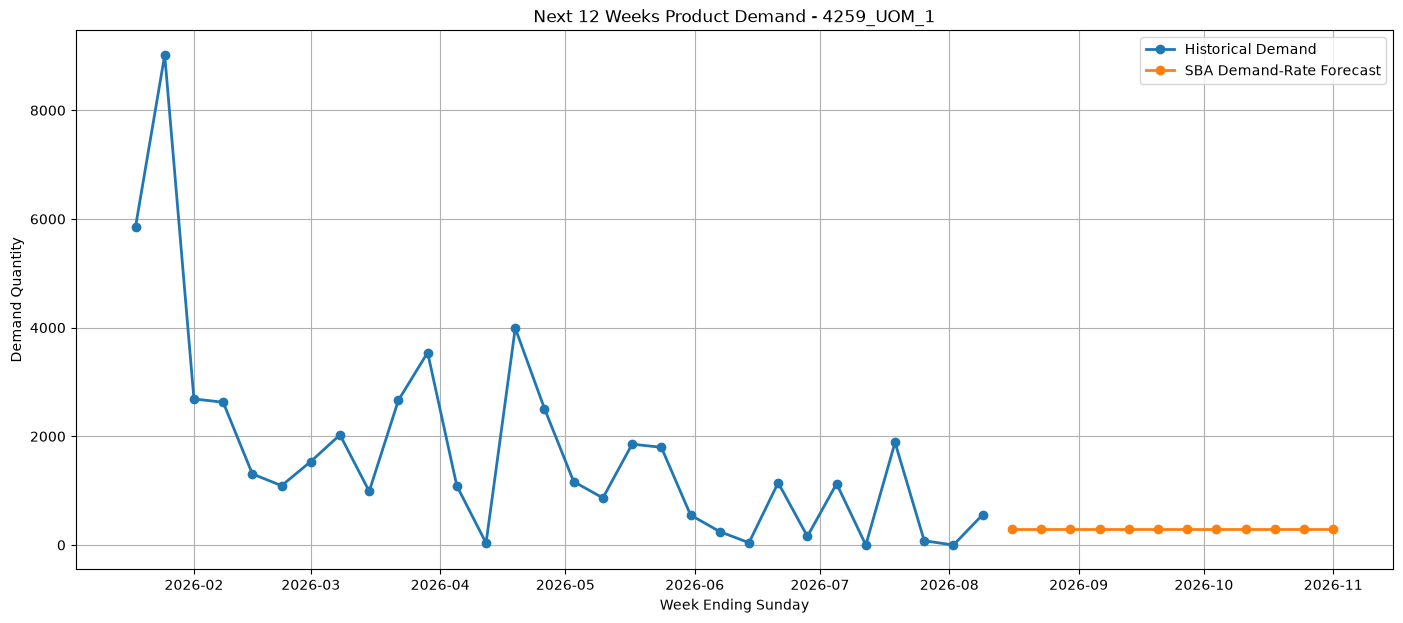

In [38]:
plt.figure(figsize=(17, 7))

recent_history = series.tail(30)

plt.plot(
    recent_history.index,
    recent_history.values,
    marker="o",
    linewidth=2,
    label="Historical Demand"
)

plt.plot(
    future_df["week_ending"],
    future_df["forecast_qty"],
    marker="o",
    linewidth=2,
    label=(
        best_variant.upper()
        + " Demand-Rate Forecast"
    )
)

plt.title(
    f"Next {FORECAST_WEEKS} Weeks "
    "Product Demand - "
    + TARGET_SKU_KEY
)

plt.xlabel("Week Ending Sunday")
plt.ylabel("Demand Quantity")

plt.legend()
plt.grid(True)
plt.show()

## Export selected-product results

In [39]:
future_df.to_csv(
    "rolling_cv_product_demand_12_week_forecast.csv",
    index=False
)

comparison_metrics.to_csv(
    "rolling_cv_final_model_comparison.csv",
    index=False
)

rolling_results.to_csv(
    "rolling_cv_parameter_results.csv",
    index=False
)

best_fold_details.to_csv(
    "rolling_cv_best_model_fold_results.csv",
    index=False
)

print(
    "Exported selected-product results."
)

Exported selected-product results.


# Batch Evaluation Across Multiple SKUs

Different Stock Keeping Units may choose different models.

## Helper: select Croston-family model using rolling CV

In [40]:
def select_croston_by_rolling_cv(
    train_series,
    alpha_grid,
    initial_train_weeks=None,
    validation_weeks=4,
    step_weeks=4
):

    if initial_train_weeks is None:

        initial_train_weeks = min(
            30,
            max(
                12,
                len(train_series) // 2
            )
        )

    summary, _ = rolling_cv_croston(
        train=train_series,
        alpha_grid=alpha_grid,
        initial_train_weeks=initial_train_weeks,
        validation_weeks=validation_weeks,
        step_weeks=step_weeks
    )

    if summary.empty:
        return None

    best = summary.iloc[0]

    return {
        "variant": best["variant"],
        "alpha": float(best["alpha"]),
        "mean_cv_WAPE": best["mean_WAPE"]
    }

## Helper: walk-forward Croston-family test

In [41]:
def walk_forward_croston(
    train_series,
    test_series,
    alpha,
    variant
):

    history = list(
        train_series.values
    )

    predictions = []

    for actual in test_series.values:

        model = croston_fit(
            history,
            alpha=alpha,
            variant=variant
        )

        predictions.append(
            model["forecast"]
        )

        history.append(
            float(actual)
        )

    return np.asarray(
        predictions,
        dtype=float
    )

## Evaluate top 20 SKUs

In [42]:
TOP_N = min(
    20,
    len(product_profile)
)

batch_rows = []

for _, product_row in (
    product_profile
    .head(TOP_N)
    .iterrows()
):

    sku = product_row["sku_key"]

    sku_series = build_weekly_series(
        df,
        sku,
        all_weeks
    )

    if len(sku_series) < 20:
        continue

    sku_test_size = min(
        8,
        max(
            4,
            len(sku_series) // 5
        )
    )

    sku_train = sku_series.iloc[
        :-sku_test_size
    ]

    sku_test = sku_series.iloc[
        -sku_test_size:
    ]

    candidate_predictions = {
        "Last-Week Naive":
            np.repeat(
                sku_train.iloc[-1],
                len(sku_test)
            ),

        "Four-Week Mean":
            np.repeat(
                sku_train.tail(4).mean(),
                len(sku_test)
            ),

        "Four-Week Median":
            np.repeat(
                sku_train.tail(4).median(),
                len(sku_test)
            )
    }

    selected_croston = (
        select_croston_by_rolling_cv(
            sku_train,
            alpha_grid
        )
    )

    if selected_croston is not None:

        croston_walk = walk_forward_croston(
            sku_train,
            sku_test,
            alpha=selected_croston["alpha"],
            variant=selected_croston["variant"]
        )

        model_label = (
            "Rolling CV + Walk-Forward "
            + selected_croston["variant"].upper()
        )

        candidate_predictions[
            model_label
        ] = croston_walk

    for model_name, pred in (
        candidate_predictions.items()
    ):

        metrics = get_metrics(
            sku_test,
            pred
        )

        batch_rows.append({
            "sku_key": sku,
            "sku_code": product_row["sku_code"],
            "product_id": product_row["product_id"],
            "uom_id": product_row["uom_id"],
            "model": model_name,
            "MAE": metrics["MAE"],
            "RMSE": metrics["RMSE"],
            "WAPE": metrics["WAPE"],
            "selected_alpha": (
                selected_croston["alpha"]
                if (
                    selected_croston is not None
                    and "Rolling CV" in model_name
                )
                else np.nan
            ),
            "mean_cv_WAPE": (
                selected_croston["mean_cv_WAPE"]
                if (
                    selected_croston is not None
                    and "Rolling CV" in model_name
                )
                else np.nan
            )
        })

batch_results = pd.DataFrame(
    batch_rows
)

batch_results.head(30)

,sku_key,sku_code,product_id,uom_id,model,MAE,RMSE,WAPE,selected_alpha,mean_cv_WAPE
0,4259_UOM_1,JU0093,4259,1,Last-Week Naive,598.625000,872.546345,96.610853,NaN,NaN
1,4259_UOM_1,JU0093,4259,1,Four-Week Mean,585.750000,655.191957,94.532984,NaN,NaN
2,4259_UOM_1,JU0093,4259,1,Four-Week Median,560.375000,690.189738,90.437765,NaN,NaN
3,4259_UOM_1,JU0093,4259,1,Rolling CV + Walk-Forward SBA,637.950180,717.677592,102.957463,0.50,96.445898
4,4258_UOM_1,JU0090,4258,1,Last-Week Naive,179.250000,275.028180,96.761134,NaN,NaN
5,4258_UOM_1,JU0090,4258,1,Four-Week Mean,211.875000,228.442416,114.372470,NaN,NaN
6,4258_UOM_1,JU0090,4258,1,Four-Week Median,218.250000,233.268086,117.813765,NaN,NaN
7,4258_UOM_1,JU0090,4258,1,Rolling CV + Walk-Forward SBA,175.019727,242.514160,94.477585,0.50,102.383356
8,4202_UOM_1,JU0006,4202,1,Last-Week Naive,72.750000,133.878676,100.000000,NaN,NaN
9,4202_UOM_1,JU0006,4202,1,Four-Week Mean,100.500000,119.209899,138.144330,NaN,NaN


## Best model per SKU

In [43]:
best_model_per_sku = (
    batch_results
    .sort_values(
        ["sku_key", "WAPE"]
    )
    .groupby(
        "sku_key",
        as_index=False
    )
    .first()
    .sort_values("WAPE")
)

best_model_per_sku[[
    "sku_key",
    "sku_code",
    "product_id",
    "uom_id",
    "model",
    "MAE",
    "RMSE",
    "WAPE",
    "selected_alpha",
    "mean_cv_WAPE"
]]

,sku_key,sku_code,product_id,uom_id,model,MAE,RMSE,WAPE,selected_alpha,mean_cv_WAPE
12,4305_UOM_1,JU0196,4305,1,Rolling CV + Walk-Forward SBA,40.186699,46.067622,63.915226,0.50,97.068397
18,4370_UOM_1,JMP0048,4370,1,Last-Week Naive,33.000000,44.899889,84.615385,0.50,160.901263
8,4259_UOM_1,JU0093,4259,1,Four-Week Median,560.375000,690.189738,90.437765,0.50,96.445898
17,4367_UOM_1,JMP0011,4367,1,Last-Week Naive,93.875000,161.638872,91.251519,0.50,126.183160
7,4258_UOM_1,JU0090,4258,1,Rolling CV + Walk-Forward SBA,175.019727,242.514160,94.477585,0.50,102.383356
15,4320_UOM_1,JMP0067,4320,1,Four-Week Median,107.250000,166.587815,94.701987,0.50,73.003433
19,4371_UOM_1,JMP0046,4371,1,Rolling CV + Walk-Forward SBA,78.422958,128.809523,95.058131,0.50,119.422133
6,4238_UOM_1,JU0051,4238,1,Last-Week Naive,18.000000,31.855141,96.000000,0.50,121.337075
11,4263_UOM_1,JU0099,4263,1,Last-Week Naive,9.000000,18.973666,100.000000,0.50,143.743211
4,4217_UOM_1,JU0024,4217,1,Last-Week Naive,24.000000,47.717921,100.000000,0.50,171.935026


## Count model winners

In [44]:
best_model_per_sku[
    "model"
].value_counts()

model
Last-Week Naive                  15
Rolling CV + Walk-Forward SBA     3
Four-Week Median                  2
Name: count, dtype: int64

## Export batch results

In [45]:
product_profile.to_csv(
    "rolling_cv_product_demand_profile.csv",
    index=False
)

batch_results.to_csv(
    "rolling_cv_product_model_backtest_results.csv",
    index=False
)

best_model_per_sku.to_csv(
    "rolling_cv_best_model_per_product.csv",
    index=False
)

print(
    "Exported batch forecasting results."
)

Exported batch forecasting results.


# Final logic

```text
SKU weekly demand
       ↓
Simple baselines
       ↓
Rolling cross-validation
       ↓
Choose Croston or SBA + alpha
       ↓
Walk-forward evaluation on untouched test
       ↓
Compare all models by WAPE
       ↓
Choose the best model for that SKU
```

Do not assume Croston or Syntetos-Boylan Approximation must win. The lowest untouched-test Weighted Absolute Percentage Error wins.